# Effects

You will build: a story sentence whose words smoke, shine, blow, burn and snow while staying text, gooey
blobs, hand-drawn outlines and an effect of your own.

Run it from this folder with ``python effects.py``, or open ``effects.ipynb``; the SVGs play in the notebook.

In [1]:
import svgwriter as svg

`text[a:b].effect("fire")` puts an animated effect on some words of a line; they stay real text.

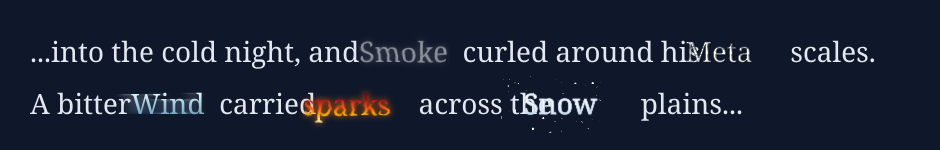

In [2]:
LINES = ("...into the cold night, and Smoke curled around his Metal scales.",
         "A bitter Wind carried sparks across the Snow plains...")
WORDS = {"Smoke": "smoke", "Metal": "metal", "Wind": "wind", "sparks": "fire", "Snow": "snow"}

sentence = svg.Document(940, 150)
sentence.rect(0, 0, 940, 150, fill="#0f172a")
for row, words in enumerate(LINES):
    line = sentence.text(words, x=30, y=62 + row * 52, font_size=28, fill="#e2e8f0", font_family="Georgia, serif")
    for word, effect in WORDS.items():
        if word in words:
            start = words.index(word)
            line[start:start + len(word)].effect(effect)
sentence.save("25_sentence.svg")
sentence.save("25_sentence.gif")
sentence

The same effects work on shapes.

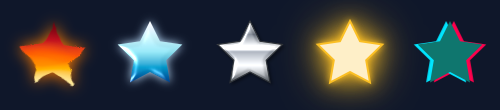

In [3]:
shapes = svg.Document(500, 110)
shapes.rect(0, 0, 500, 110, fill="#0f172a")
for column, effect in enumerate(("fire", "ice", "metal", "neon", "glitch")):
    shapes.add(svg.paths.star(50 + column * 100, 55, 34, points=5)).effect(effect)
shapes.save("25_shapes.svg")
shapes

`svg.filters.goo` melts shapes that come close: two drops stretch a bridge before they part.

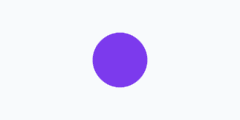

In [4]:
goo = svg.Document(240, 120)
goo.rect(0, 0, 240, 120, fill="#f8fafc")
with goo.group(fill="#7c3aed") as blobs:
    goo.circle(120, 60, 26)
    for shift in (-70, 70):
        drop = goo.circle(120, 60, 18)
        drop.animate.move_by(shift, 0, 1.5).move_by(-shift, 0, 1.5, begin=1.5)
blobs.filter = svg.filters.goo(10)
goo.save("25_goo.svg")
goo.save("25_goo.gif")
goo

Path effects reshape an outline: `roughen` makes it hand-drawn, `dashed` cuts it into dashes, `taper` makes a brush stroke.

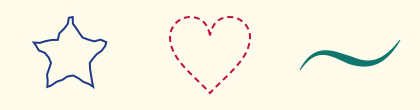

In [5]:
strokes = svg.Document(420, 110)
strokes.rect(0, 0, 420, 110, fill="#fffbeb")
star = svg.paths.star(70, 55, 40, points=5, fill="none", stroke="#1e3a8a", stroke_width=2)
strokes += star.roughen(6, 2)
strokes += svg.paths.heart(210, 55, 80, fill="none", stroke="#be123c", stroke_width=2).dashed(6, 4)
wave = svg.path("M300 70 C330 20 360 100 400 40", fill="#0f766e")
strokes += wave.taper(1, 8, 1)
strokes.save("25_strokes.svg")
strokes

Make your own: `@svg.preset.effect` registers a function by name, and it works like the built-in ones.
(`@svg.preset.pattern`, `filter`, `gradient` and `marker` do the same.)

In [6]:
@svg.preset.effect
def ember(element: svg.Element, *, color: str = "#f97316") -> None:
    """Glowing coals: the fire gradient without the flames."""
    element.fill = svg.gradients.blend("#fde68a", color, "#7f1d1d", angle=-90)
    element.filter = svg.filters.glow(3, color=color)


embers = svg.Document(320, 60)
embers.rect(0, 0, 320, 60, fill="#111827")
title = embers.text("still warm", x=20, y=42, font_size=32, font_weight="bold", fill="#e2e8f0")
title[6:].effect("ember")
embers
embers.save("25_ember.svg")